# SynCOM with dask (trial)

This notebook tries **dask** to make SynCOM runs faster and bigger, **without changing any module**:
- **Frames in parallel.** `syncom_image` and `add_planets` are the existing functions. dask runs several time steps at once on worker processes, one frame per task.
- **The cube on disk.** Each worker writes its frame straight into an uncompressed zarr array (`<runs folder>/<run>/cubes/<run>_cube.zarr`, float64, one chunk per frame). The cube does not have to fit in RAM, and no saving step is left at the end. The whole pipeline uses only zarr: the cube and its metadata are zarr stores, and the movies and frames are read from them (no `.npz`).
- **Field 5–`R_MAX` R☉.** NY follows from `R_MAX` and the pixel size.
- **Nothing loads the whole cube.** Plots read single frames from the zarr (`cube_z[:, :, k]`); the movies and the FITS files are made by the workers, each reading its own frames. RAM stays at a few frames per worker, whatever the run size: only the disk limits it.

The frames are the same as the current `syncom_core`, bit for bit (checked below). Everything goes to `<runs folder>/SynCOM_dasktrial_.../`, so no real run is overwritten. The runs folder is set by `STORAGE` in Settings: the external drive or `SynCOM_runs/` on this Mac.

## Settings
- `R_MAX` sets the top of the field; `NY = ceil((R_MAX − 5) / PIXEL) + 1`, so the field reaches at least `R_MAX`.
- `N_WORKERS` is the number of dask worker processes (this Mac has 10 cores).
- `N_CHECK` frames are also made with the current `syncom_core`, to compare.
- `STORAGE` sets where the runs are saved: `"auto"` (the external drive `EXTERNAL_DRIVE` when it is connected, otherwise this Mac), `"external"` (the drive only; error if it is not connected) or `"local"` (`SynCOM_runs/` next to the code). Runs on the drive go to `EXTERNAL_RUNS_DIR`. The cell prints where the run goes and the free space there, and warns if the cube does not fit.
- On the external drive (exFAT), keep it connected and the Mac awake during a run: unplugging it while frames are written can corrupt them.

In [1]:
import os, time, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import zarr
from astropy.time import Time
from dask.distributed import Client, LocalCluster, as_completed
from punchbowl.data.visualize import cmap_punch

from syncom_prams import default_syncom_prams, polar_ranges
from syncom_load import syncom_load, syncom_blob_table, syncom_planet_table, planet_sigmas
from syncom_image import syncom_image, angular_profiles
from syncom_core import syncom_core, _print_planet_summary
import syncom_path
from syncom_path import syncom_run_name, syncom_output_path
from syncom_movie import save_syncom_movie, save_rect_movie, plot_syncom_image, plot_rect_image
from syncom_fits import write_fits_frames
from polar_to_rect import polar_to_rect

PIXEL = 0.0225                                  # [Rsun] radial pixel size
R_MAX = 180.0                                    # [Rsun] top of the field
NY = int(np.ceil((R_MAX - 5.0) / PIXEL)) + 1    # radial pixels: 5 Rsun ... >= R_MAX
N_BLOBS = 1000
scaleFactor = 1.0
PLANETS = ("mercury", "jupiter", "mars", "venus",)   # Mars and Venus are near 170 Rsun on this date: outside a 5-80 Rsun field
START_TIME = Time("2026-07-26T06:40:00", scale="utc")
N_FRAMES = 100                                  # time steps 0 ... N_FRAMES-1
N_WORKERS = 4                                   # dask worker processes (4 was the fastest on this Mac)
# N_CHECK = 50                                     # frames also made with the current syncom_core
TRIAL_VERSION = "sample-4_planets-180_Rs"

# Where the runs are saved (cube, metadata, movies, FITS):
#   "auto"     -> the external drive when it is connected, otherwise this Mac
#   "external" -> the external drive only (error if it is not connected)
#   "local"    -> SynCOM_runs/ next to the code, on this Mac
STORAGE = "auto"
EXTERNAL_DRIVE = Path("/Volumes/X10_Pro")
EXTERNAL_RUNS_DIR = EXTERNAL_DRIVE / "Research" / "SynCOM" / "SynCOM_python-current_version" / "SynCOM_runs"
LOCAL_RUNS_DIR = Path("SynCOM_runs")

params = default_syncom_prams(SYNCOM_NY=NY, SYNCOM_PIXEL=PIXEL, SYNCOM_N_BLOBS=N_BLOBS, SYNCOM_SCALE_FACTOR=scaleFactor,
                              SYNCOM_PLANETS=PLANETS, SYNCOM_START_TIME=START_TIME.isot)
TRIAL_RUN = syncom_run_name(TRIAL_VERSION, N_BLOBS, scaleFactor)
phi_range, rho_range = polar_ranges(params)
print(f"NY = {NY}: field {rho_range[0]:.2f}-{rho_range[1]:.3f} Rsun;  {N_FRAMES} frames = "
      f"{params['syncom_nx'] * NY * N_FRAMES * 8 / 1e9:.1f} GB;  run {TRIAL_RUN}")

# storage: every later cell (and syncom_output_path) uses syncom_path.RUNS_DIR
if STORAGE not in ("auto", "external", "local"):
    raise ValueError(f'STORAGE must be "auto", "external" or "local", got {STORAGE!r}')
drive_connected = os.path.ismount(EXTERNAL_DRIVE)
if STORAGE == "external" and not drive_connected:
    raise FileNotFoundError(f"{EXTERNAL_DRIVE} is not connected; connect it or use STORAGE = \"local\"")
on_drive = STORAGE == "external" or (STORAGE == "auto" and drive_connected)
syncom_path.RUNS_DIR = EXTERNAL_RUNS_DIR if on_drive else LOCAL_RUNS_DIR
syncom_path.RUNS_DIR.mkdir(parents=True, exist_ok=True)
cube_bytes = params["syncom_nx"] * NY * N_FRAMES * 8
free_bytes = shutil.disk_usage(syncom_path.RUNS_DIR).free
where = f"external drive {EXTERNAL_DRIVE.name}" if on_drive else "this Mac"
print(f"runs saved on {where}: {syncom_path.RUNS_DIR.resolve()}  ({free_bytes / 1e9:.0f} GB free)")
if STORAGE == "auto" and not drive_connected:
    print(f"⚠️ {EXTERNAL_DRIVE} is not connected: saving on this Mac")
if cube_bytes > free_bytes:
    print(f"⚠️ the cube needs {cube_bytes / 1e9:.1f} GB but only {free_bytes / 1e9:.1f} GB are free there: "
          "use fewer frames, a smaller field, or the external drive")


No file or date entered. Using default: syncom_20140414_densfix.sav
NY = 7779: field 5.00-180.005 Rsun;  100 frames = 22.4 GB;  run SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0
runs saved on external drive X10_Pro: /Volumes/X10_Pro/Research/SynCOM/SynCOM_python-current_version/SynCOM_runs  (2102 GB free)


## 1. Start the dask workers

### What it does
Starts `N_WORKERS` worker processes on this machine, one thread each. Each worker's math library is set to one thread, so the workers don't compete for the cores. The dashboard link shows the tasks and memory live while a run goes.

### Expected behaviour
It prints the dashboard link and the number of workers.

In [2]:
for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[var] = "1"          # inherited by the worker processes started below
cluster = LocalCluster(n_workers=N_WORKERS, threads_per_worker=1, processes=True)
client = Client(cluster)
client.wait_for_workers(N_WORKERS)  # all workers up before the run starts
nthreads = client.nthreads()        # {worker address: threads} for every worker (scheduler_info() lists only 5 by default)
print("dashboard:", client.dashboard_link, f";  {len(nthreads)} workers, {sum(nthreads.values())} threads")

dashboard: http://127.0.0.1:8787/status ;  4 workers, 4 threads


## 2. `syncom_core_dask`: frames in parallel, written to zarr

### What it does
It does what `syncom_core` does, with the frames shared among the dask workers:
1. On this notebook's process: loads the blobs, builds the blob table and angular profiles once, and computes the planet tracks once (all as in `syncom_core`). With planets, the first blob-only frame gives each planet's local fluctuation, as in `syncom_core`.
2. Creates `<runs folder>/<run>/cubes/<run>_cube.zarr`: shape `[NX, NY, NT]`, float64, **no compression**, one chunk per frame. The parameters, blob table input, planet tracks, `sigma_syn` and `time0` go to `<run>_cube_meta.zarr` next to it (a small zarr group: arrays as zarr arrays, numbers and strings as attributes). `load_meta_zarr` reads them back exactly.
3. Sends the blob table and angular profiles to every worker once. Then each time step is a task: the worker computes the frame with `syncom_image`, adds the planets with `add_planets`, and writes the frame into its chunk of the zarr array.

It returns the zarr array, which reads frames from disk only when they are used.

### Expected behaviour
- It prints the planet summary, the progress at 25/50/75 %, the time per frame and the zarr written.
- Before starting it checks that the disk has room for the cube.
- If a task fails, the error is raised here.

In [3]:
def _write_frame(params, blobs, gx, planets, sigma_syn, t, time0, zarr_path):
    # runs on a worker: one frame, exactly as syncom_core makes it, written into its chunk
    import zarr
    from syncom_image import syncom_image
    from syncom_planets import add_planets
    img = syncom_image(params, blobs, t, gx=gx)
    if planets is not None:
        add_planets(img, params, planets, t, sigma_syn)
    zarr.open_array(zarr_path, mode="r+")[:, :, t - time0] = img
    return t


def _remove_tree(path):
    # Deletes a folder (an old zarr cube). On exFAT drives macOS keeps a hidden "._name" file next to each file
    # and deletes it together with "name", so files that are already gone are skipped
    def skip_missing(func, p, exc):
        if not isinstance(exc, FileNotFoundError):
            raise exc
    shutil.rmtree(path, onexc=skip_missing)


def _json_value(v):
    # numpy scalars and 0-d arrays -> plain Python values (JSON attributes)
    if isinstance(v, np.ndarray) and v.ndim == 0:
        v = v[()]
    return v.item() if isinstance(v, np.generic) else v


def _write_meta_group(group, d):
    # numeric and bool arrays -> uncompressed zarr arrays; dicts -> subgroups;
    # numbers, strings, None, tuples and string arrays -> JSON attributes (types noted to restore them exactly)
    values, tuples, str_arrays = {}, [], []
    for key, v in d.items():
        if isinstance(v, dict):
            _write_meta_group(group.create_group(key), v)
        elif isinstance(v, np.ndarray) and v.ndim > 0 and v.dtype.kind in "biuf":
            group.create_array(key, shape=v.shape, dtype=v.dtype, chunks=v.shape, compressors=None)[...] = v
        elif isinstance(v, np.ndarray) and v.ndim > 0 and v.dtype.kind == "U":
            values[key] = v.tolist(); str_arrays.append(key)
        elif isinstance(v, tuple):
            values[key] = [_json_value(x) for x in v]; tuples.append(key)
        else:
            values[key] = _json_value(v)
    group.attrs.update(values=values, tuples=tuples, str_arrays=str_arrays)


def save_meta_zarr(path, meta):
    """Writes the run's metadata (params, LoadStruc, planets, sigma_syn, time0, ...) as a zarr group."""
    path = Path(path)
    if path.exists():
        _remove_tree(path)
    _write_meta_group(zarr.open_group(str(path), mode="w"), meta)


def _read_meta_group(group):
    a = group.attrs.asdict()
    d = {}
    for key, v in a["values"].items():
        d[key] = np.array(v) if key in a["str_arrays"] else tuple(v) if key in a["tuples"] else v
    for key, arr in group.arrays():
        d[key] = arr[...]
    for key, sub in group.groups():
        d[key] = _read_meta_group(sub)
    return d


def load_meta_zarr(path):
    """The metadata dict written by save_meta_zarr."""
    return _read_meta_group(zarr.open_group(str(path), mode="r"))


def syncom_core_dask(N_BLOBS, time0, time_t, client, syncom_version="v1", scale_factor=None, simple=False,
                     params=None, LoadStruc=None):
    start_time = time.time()
    if N_BLOBS != params["syncom_n_blobs"]:
        raise ValueError(f"N_BLOBS = {N_BLOBS} but params['syncom_n_blobs'] = {params['syncom_n_blobs']}")
    nx, ny, nt = params["syncom_nx"], params["syncom_ny"], time_t - time0
    scalefactor = scale_factor if scale_factor is not None else params["syncom_scale_factor"]
    params["syncom_scale_factor"] = scalefactor

    # 1. computed once, as in syncom_core
    if LoadStruc is None:
        LoadStruc = syncom_load(params, simple=simple)
    blobs = syncom_blob_table(params, LoadStruc, scalefactor)
    gx = angular_profiles(params, blobs)
    planets = syncom_planet_table(params, time0, time_t)
    sigma_syn = None
    if planets is not None:
        _print_planet_summary(planets, params)
        sigma_syn = planet_sigmas(syncom_image(params, blobs, time0, gx=gx), planets)   # first blob-only frame

    # 2. the cube on disk: uncompressed zarr, one chunk per frame
    run_name = syncom_run_name(syncom_version, params["syncom_n_blobs"], scalefactor)
    zarr_path = syncom_output_path(run_name, "cubes", "cube.zarr")
    meta_path = syncom_output_path(run_name, "cubes", "cube_meta.zarr")
    need, free = nx * ny * nt * 8, shutil.disk_usage(zarr_path.parent).free
    if need > free:
        raise OSError(f"the cube needs {need / 1e9:.1f} GB but only {free / 1e9:.1f} GB are free on {zarr_path.parent}")
    if zarr_path.exists():
        print(f"  replacing the existing cube {zarr_path.name}")
        _remove_tree(zarr_path)
    z = zarr.create_array(store=str(zarr_path), shape=(nx, ny, nt), chunks=(nx, ny, 1), dtype="float64",
                          compressors=None, overwrite=True)
    z.attrs.update(run_name=run_name, time0=time0, time_t=time_t, frames_done=0,
                   layout="[NX, NY, NT] = [position angle, radius, time step], one chunk per frame")
    save_meta_zarr(meta_path, dict(params=params, LoadStruc=LoadStruc, scale_factor=scalefactor, planets=planets,
                                   sigma_syn=sigma_syn, time0=time0))

    # 3. one task per time step; the large inputs are sent to every worker once
    blobs_w, gx_w = client.scatter([blobs, gx], broadcast=True)
    steps = list(range(time0, time_t))
    futures = client.map(_write_frame, [params] * nt, [blobs_w] * nt, [gx_w] * nt, [planets] * nt,
                         [sigma_syn] * nt, steps, [time0] * nt, [str(zarr_path.resolve())] * nt, pure=False)
    print(f"  0% (0/{nt} frames, {len(client.nthreads())} workers)")
    done, quarter = 0, 1
    for future in as_completed(futures):
        future.result()                                   # raises here if a frame failed
        done += 1
        while quarter < 4 and done * 4 >= quarter * nt:
            print(f"  {quarter * 25}% ({done}/{nt} frames, {time.time() - start_time:.0f} s)")
            quarter += 1
    z.attrs["frames_done"] = nt
    elapsed = time.time() - start_time
    print(f"  done ({nt} frames, {elapsed:.0f} s, {elapsed / nt:.2f} s per frame)")
    print(f"✅ Saved: {zarr_path} ({nx * ny * nt * 8 / 1e9:.1f} GB, uncompressed) and {meta_path.name}")
    return zarr.open_array(str(zarr_path), mode="r")

In [4]:
cube_z = syncom_core_dask(N_BLOBS, 0, N_FRAMES, client, syncom_version=TRIAL_VERSION, scale_factor=scaleFactor,
                          simple=True, params=params)
print(cube_z.shape, "[NX, NY, NT];  chunks", cube_z.chunks)

  Mercury: r 65.21 -> 66.06 Rsun, PA 262.74 -> 263.13 deg, dr/dt 0.382 px/frame (19.9 km/s), V +1.30, S/N 2346 (saturated), in view 100/100 frames
  Jupiter: r 9.21 -> 8.26 Rsun, PA 83.74 -> 82.41 deg, dr/dt -0.422 px/frame (-22.0 km/s), V -1.78, S/N 2182 (saturated), in view 100/100 frames
  Jupiter is outside the radii where PUNCH was measured for part of the run: S/N and shape use the nearest measured radius
  Mars: r 168.24 -> 168.59 Rsun, PA 274.96 -> 274.94 deg, dr/dt 0.158 px/frame (8.2 km/s), V +1.31, S/N 5027, in view 100/100 frames
  Venus: r 170.48 -> 170.61 Rsun, PA 94.31 -> 94.32 deg, dr/dt 0.060 px/frame (3.1 km/s), V -4.24, S/N 5761 (saturated), in view 100/100 frames
  0% (0/100 frames, 4 workers)
  25% (25/100 frames, 45 s)
  50% (50/100 frames, 81 s)
  75% (75/100 frames, 120 s)
  done (100 frames, 154 s, 1.54 s per frame)
✅ Saved: /Volumes/X10_Pro/Research/SynCOM/SynCOM_python-current_version/SynCOM_runs/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0/cu

### Same frames as the current `syncom_core`
The first `N_CHECK` frames again with the current `syncom_core` (sequential, in RAM, nothing saved), planets included.

**Expected:** every frame identical (`np.array_equal`), because the same functions make each frame.

In [5]:
# t0 = time.time()
# ref = syncom_core(N_BLOBS, 0, N_CHECK, scale_factor=scaleFactor, simple=True, save=False, params=params)
# t_seq = (time.time() - t0) / N_CHECK
# for k in range(N_CHECK):
#     same = np.array_equal(ref[:, :, k], cube_z[:, :, k])
#     print(f"frame {k}: identical {same}")
#     assert same
# print(f"current syncom_core: {t_seq:.2f} s per frame (sequential)")
# del ref

## 3. The zarr cube: frames on demand

### What it does
`cube_z` is the zarr array returned by `syncom_core_dask`. Indexing it reads only what is asked for: `cube_z[:, :, k]` reads frame `k` from disk (one numpy frame, `[NX, NY]`), nothing else. The cube is never loaded into RAM as a whole.

The run's metadata comes from `<run>_cube_meta.zarr` (`load_meta_zarr`): the parameters, blob table input, planet tracks, `sigma_syn` and `time0`.

To work on a run made earlier (no simulation), uncomment the two lines at the top and set its run name; then run the section 1 cell (workers) and continue from here.

### Expected behaviour
- It prints the cube shape, its size on disk, the frames finished and the time steps.
- A warning if the run was interrupted (`frames_done` smaller than the number of frames).


In [6]:
# An existing run instead of the one just made (then run section 1 for the workers):
# TRIAL_RUN = "SynCOM_dasktrial-2_N_BLOBS_1000_SCALE_FACTOR_1.0"
# cube_z = zarr.open_array(str(syncom_output_path(TRIAL_RUN, "cubes", "cube.zarr")), mode="r")

zarr_path = syncom_output_path(TRIAL_RUN, "cubes", "cube.zarr")
meta = load_meta_zarr(syncom_output_path(TRIAL_RUN, "cubes", "cube_meta.zarr"))
params = meta["params"]                     # the run's own parameters (identical to Settings for this run)
time0 = int(meta["time0"])
done = cube_z.attrs.get("frames_done", cube_z.shape[2])
print(f"{TRIAL_RUN}: cube {cube_z.shape} [NX, NY, NT], {cube_z.nbytes / 1e9:.1f} GB on disk, "
      f"time steps {time0}-{time0 + cube_z.shape[2] - 1}")
if done < cube_z.shape[2]:
    print(f"⚠️ only {done} of {cube_z.shape[2]} frames were finished")


SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0: cube (3600, 7779, 100) [NX, NY, NT], 22.4 GB on disk, time steps 0-99


/Users/valmirmoraesfilho/miniforge3/envs/syncom-punch/lib/python3.12/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at ._params is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/Users/valmirmoraesfilho/miniforge3/envs/syncom-punch/lib/python3.12/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at ._zarr.json is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/Users/valmirmoraesfilho/miniforge3/envs/syncom-punch/lib/python3.12/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at ._LoadStruc is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/Users/valmirmoraesfilho/miniforge3/envs/syncom-punch/lib/python3.12/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at ._planets is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/Users/valmirmoraesfilho/miniforge3/envs/syncom-punch/lib/python3.12/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object a

## 4. Plots and movies with the existing functions

### What it does
Frame 0 in polar and Cartesian form with the current functions of `syncom_movie.py` and `polar_to_rect.py`, on frame 0 read from the zarr (`cube_z[:, :, 0]`, one frame in RAM). Then the polar and Cartesian movies of every frame, drawn by the dask workers straight from the zarr (`save_movie_dask`, below).

### Expected behaviour
- The polar axes run from 5 R☉ to the top of the field (`R_MAX`); the planets inside the field are drawn, the ones outside are not.
- The two movies are written to `<runs folder>/<run>/movies/`.

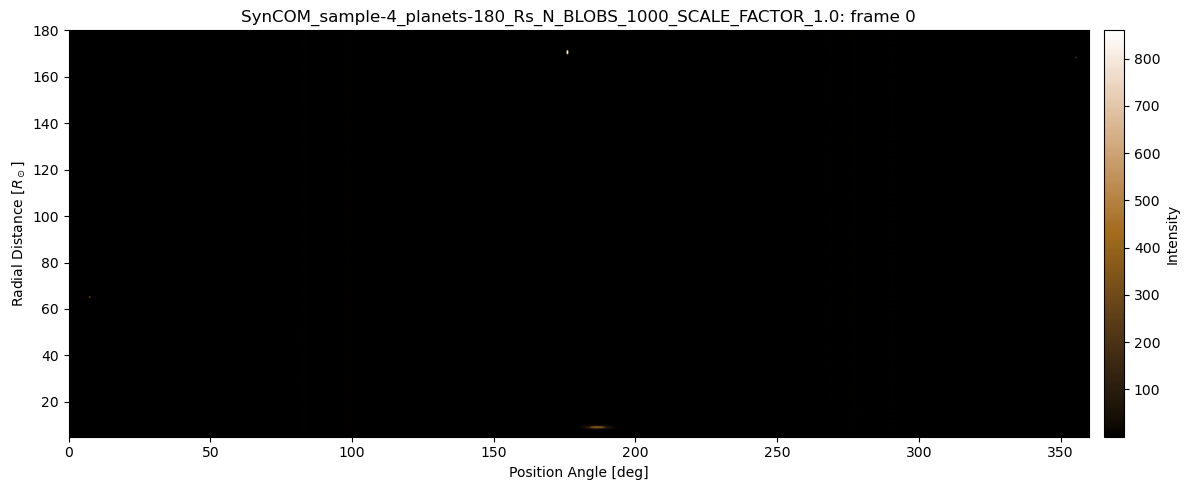

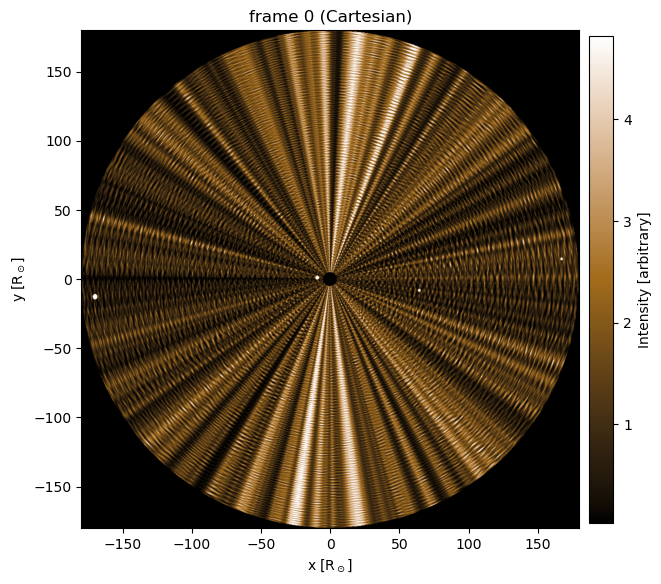

In [7]:
frame0 = cube_z[:, :, 0]                    # one frame from the zarr
plot_syncom_image(frame0, title=f"{TRIAL_RUN}: frame 0", params=params)
plot_rect_image(polar_to_rect(frame0, params=params, n=1024), params=params, title="frame 0 (Cartesian)",
                vmin=np.percentile(frame0[::8, ::8], 1), vmax=np.percentile(frame0[::8, ::8], 99.5))
del frame0


### Movies with dask: `save_movie_dask`

#### What it does
`save_movie_dask(kind, zarr_path, filename, title, client, params, frames=None, max_workers=4)` makes the same movie as `save_syncom_movie` (`kind="polar"`) or `save_rect_movie` (`kind="rect"`), straight from the zarr cube:
- Each dask worker reads its frames from the zarr and draws them with the same figure as the module function (size, margins, axes, colour bar, title, colour limits). It sends back the finished image.
- This notebook passes the images to ffmpeg in order, with the same settings as the module.
- The cube is never loaded into RAM, so every frame of the run can go into the movie.
- Drawing uses at most `max_workers` workers. On this Mac (4 performance cores), 4 workers drew faster than 8.

#### Expected behaviour
- Needs the dask workers of section 1. After opening an existing zarr, run the section 1 cell first.
- The `.mp4` is byte for byte the file `save_syncom_movie` / `save_rect_movie` writes for the same frames. This was checked on 20 and 60 frames of the 80 R☉ run.
- Measured for 100 frames of the 80 R☉ run: polar about 11 s (about 31 s with `save_syncom_movie`), rect about 5 s (about 9 s with `save_rect_movie`).
- It prints the progress every 50 frames and the time taken.

In [8]:
import io, threading, uuid
from pathlib import Path
import dask.array as da
from collections import deque
from matplotlib import animation
from matplotlib.figure import Figure
from mpl_toolkits.axes_grid1 import make_axes_locatable
from astropy.time import TimeDelta
from distributed import get_worker
from syncom_movie import _polar_extent, _run_timing
from polar_to_rect import rect_sampling, apply_rect_sampling


def _frame_title(style, i, k):
    # same text as save_syncom_movie / save_rect_movie
    if style["start_time"] is None:
        return f"{style['title']}   t = {k * style['cadence']:.0f} s   frame {i + 1}/{style['n_frames']}"
    t = (Time(style["start_time"], scale="utc") + TimeDelta(k * style["cadence"], format="sec")).isot
    return f"{style['title']}   {t} UTC   frame {i + 1}/{style['n_frames']}"


def _movie_figure(style, img):
    # the figure of save_syncom_movie (polar) or save_rect_movie (rect): same size, margins, axes and colour bar
    fig = Figure(figsize=style["figsize"])
    ax = fig.subplots()
    if style["kind"] == "polar":
        fig.subplots_adjust(left=0.07, right=0.93, bottom=0.12, top=0.88)
        im = ax.imshow(img, origin="lower", aspect="auto", cmap=style["cmap"], vmin=style["vmin"], vmax=style["vmax"],
                       extent=style["extent"])
        cax = make_axes_locatable(ax).append_axes("right", size="2%", pad=0.12)
        ax.set_xlabel("Position Angle [deg]")
        ax.set_ylabel(r"Radial Distance [$R_\odot$]")
    else:
        fig.subplots_adjust(left=0.09, right=0.9, bottom=0.07, top=0.93)
        r = style["rho_max"]
        im = ax.imshow(img, origin="lower", cmap=style["cmap"], vmin=style["vmin"], vmax=style["vmax"],
                       extent=[-r, r, -r, r])
        cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.12)
        ax.set_xlabel(r"X [$R_\odot$]")
        ax.set_ylabel(r"Y [$R_\odot$]")
    fig.colorbar(im, cax=cax, label=style["label"])
    ttl = fig.suptitle("", fontsize=11)
    return fig, im, ttl


def _render_frame(style, sampling, i, k):
    # runs on a worker: reads frame k from the zarr, draws it, returns the RGBA bytes that ffmpeg takes
    import zarr
    frame = zarr.open_array(style["zarr_path"], mode="r")[:, :, k]
    if style["kind"] == "polar":
        img = frame.T
    else:
        r = apply_rect_sampling(frame, sampling)
        img = np.where(r == 0, np.nan, r).T
    # one figure per worker thread and movie, reused for every frame it draws (matplotlib is not thread-safe)
    figs = get_worker().__dict__.setdefault("_syncom_movie_figs", {})
    key = (style["id"], threading.get_ident())
    if key not in figs:
        for old in [o for o in figs if o[0] != style["id"]]:
            del figs[old]
        figs[key] = _movie_figure(style, img)
    fig, im, ttl = figs[key]
    im.set_data(img)
    ttl.set_text(_frame_title(style, i, k))
    buf = io.BytesIO()
    fig.savefig(buf, format=style["frame_format"], dpi=style["dpi"])
    return buf.getvalue()


def save_movie_dask(kind, zarr_path, filename, title, client, params, frames=None, fps=10, cmap=cmap_punch,
                    vmin=None, vmax=None, n=1024, label="Intensity [arbitrary]", max_workers=4):
    t0 = time.time()
    zarr_path = str(Path(zarr_path).resolve())
    z = da.from_zarr(zarr_path)                                       # lazy: frames are read by the workers
    frames = list(range(z.shape[2])) if frames is None else list(frames)
    cadence, start_time = _run_timing(params, None, None)

    # one colour scale for the whole movie: the same subsample and percentiles as save_syncom_movie / save_rect_movie
    if vmin is None or vmax is None:
        step = max(1, len(frames) // 20)
        lo, hi = np.nanpercentile(z[::4, ::4, frames[::step]].compute(scheduler="threads"), [1, 99.5])
        vmin = lo if vmin is None else vmin
        vmax = hi if vmax is None else vmax

    style = dict(kind=kind, id=uuid.uuid4().hex, zarr_path=zarr_path, title=title, n_frames=len(frames),
                 cadence=cadence, start_time=None if start_time is None else start_time.isot,
                 vmin=vmin, vmax=vmax, label=label)
    sampling = None
    if kind == "polar":
        style.update(figsize=(12, 5.2), dpi=100, cmap=cmap, extent=_polar_extent(params, z.shape))
    elif kind == "rect":
        phi_range, rho_range = polar_ranges(params, shape=z.shape)
        cm = plt.get_cmap(cmap).copy()
        cm.set_bad("black")                                           # occulter and outside the field of view
        style.update(figsize=(8, 7.4), dpi=150, cmap=cm, rho_max=rho_range[1])
        sampling = client.scatter(rect_sampling(z.shape, phi_range, rho_range, n), broadcast=True)
    else:
        raise ValueError(f"kind must be 'polar' or 'rect', got {kind!r}")

    # the same ffmpeg settings as the module; the frames come from the workers, in order
    writer = animation.FFMpegWriter(fps=fps, codec="libx264",
                                    extra_args=["-pix_fmt", "yuv420p", "-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2"])
    writer.setup(Figure(figsize=style["figsize"]), str(filename), dpi=style["dpi"])
    style["frame_format"] = writer.frame_format
    # drawing on at most max_workers workers: on this Mac (4 performance cores) 4 drew faster than 8
    workers = sorted(client.nthreads())[:max_workers]
    window = 4 * len(workers)                                         # frames drawn ahead of the writer
    todo, pending = iter(enumerate(frames)), deque()
    try:
        for i, k in todo:
            pending.append(client.submit(_render_frame, style, sampling, i, k, workers=workers, pure=False))
            if len(pending) >= window:
                break
        done = 0
        while pending:
            writer._proc.stdin.write(pending.popleft().result())
            done += 1
            for i, k in todo:
                pending.append(client.submit(_render_frame, style, sampling, i, k, workers=workers, pure=False))
                break
            if done % 50 == 0:
                print(f"  {done}/{len(frames)} frames ({time.time() - t0:.0f} s)")
    finally:
        writer.finish()
    print(f"✅ Saved movie: {filename} ({len(frames)} frames at {fps} fps) in {time.time() - t0:.0f} s")
    return Path(filename)


In [9]:
# Both movies from the zarr cube, all frames (the workers of section 1 must be running)
t0 = time.time()
save_movie_dask("polar", zarr_path, syncom_output_path(TRIAL_RUN, "movies", "polar_movie.mp4"), TRIAL_RUN, client, params)
t_polar = time.time() - t0
t0 = time.time()
save_movie_dask("rect", zarr_path, syncom_output_path(TRIAL_RUN, "movies", "rect_movie.mp4"), f"{TRIAL_RUN}_rect", client, params)
t_rect = time.time() - t0
print(f"polar movie {t_polar:.0f} s, rect movie {t_rect:.0f} s")



2026-11-11 16:35:32 - matplotlib.animation - INFO: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x520 -pix_fmt rgba -framerate 10 -loglevel error -i pipe: -vcodec libx264 -pix_fmt yuv420p -vf 'scale=trunc(iw/2)*2:trunc(ih/2)*2' -y /Volumes/X10_Pro/Research/SynCOM/SynCOM_python-current_version/SynCOM_runs/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0/movies/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0_polar_movie.mp4


  50/100 frames (38 s)
  100/100 frames (56 s)
✅ Saved movie: /Volumes/X10_Pro/Research/SynCOM/SynCOM_python-current_version/SynCOM_runs/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0/movies/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0_polar_movie.mp4 (100 frames at 10 fps) in 56 s


2026-11-11 16:36:28 - matplotlib.animation - INFO: MovieWriter._run: running command: ffmpeg -f rawvideo -vcodec rawvideo -s 1200x1110 -pix_fmt rgba -framerate 10 -loglevel error -i pipe: -vcodec libx264 -pix_fmt yuv420p -vf 'scale=trunc(iw/2)*2:trunc(ih/2)*2' -y /Volumes/X10_Pro/Research/SynCOM/SynCOM_python-current_version/SynCOM_runs/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0/movies/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0_rect_movie.mp4


  50/100 frames (15 s)
  100/100 frames (26 s)
✅ Saved movie: /Volumes/X10_Pro/Research/SynCOM/SynCOM_python-current_version/SynCOM_runs/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0/movies/SynCOM_sample-4_planets-180_Rs_N_BLOBS_1000_SCALE_FACTOR_1.0_rect_movie.mp4 (100 frames at 10 fps) in 26 s
polar movie 56 s, rect movie 26 s


## 5. FITS frames with dask: `write_fits_dask`

### What it does
`write_fits_dask(zarr_path, run_name, client, params, frames=None, time0=0, overwrite=True, max_workers=4)` writes the same files as `write_fits_frames`, straight from the zarr cube:
- Each worker reads its frame from the zarr and writes `<runs folder>/<run>/FITS/<run>_<t:04d>.fts`: the image `frame.T`, shape `(NY, NX)`, float64, uncompressed, with the header of `syncom_header.syncom_fits_header` (run name, time step, DATE-OBS, WCS, model parameters, planets).
- `frames` are time steps (e.g. `range(0, 30)` or `[0, 50, 100]`); `None` writes every frame.
- The file names are made here, in the notebook: the workers don't know the runs folder chosen in Settings.
- `write_fits_frames` starts with `np.asarray(cube)`, so on a zarr cube it would read the whole cube into RAM; this version holds one frame per worker.

### Expected behaviour
- Same image data and header cards as `write_fits_frames`; only `DATE` (the time the file was written) differs.
- Before writing it checks that the disk has room (one frame = NX × NY × 8 bytes, 224 MB on the 180 R☉ grid).
- It prints the progress every 50 files and the time taken.


In [10]:
from astropy.io import fits


def _write_fits_frame(zarr_path, run_name, t, k, params, filename, overwrite):
    # runs on a worker: frame k of the zarr, written as write_fits_frames writes time step t
    import zarr
    from astropy.io import fits
    from syncom_header import syncom_fits_header
    z = zarr.open_array(zarr_path, mode="r")
    header = syncom_fits_header(run_name, t, params=params, nx=z.shape[0], ny=z.shape[1])
    fits.writeto(filename, np.asarray(z[:, :, k], dtype=np.float64).T, header=header, overwrite=overwrite)
    return filename


def write_fits_dask(zarr_path, run_name, client, params, frames=None, time0=0, overwrite=True, max_workers=4):
    t0 = time.time()
    zarr_path = str(Path(zarr_path).resolve())
    nx, ny, nt = zarr.open_array(zarr_path, mode="r").shape
    steps = list(range(time0, time0 + nt)) if frames is None else [int(t) for t in frames]
    for t in steps:
        if not 0 <= t - time0 < nt:
            raise IndexError(f"time step {t} is outside the cube (time steps {time0}..{time0 + nt - 1})")
    if not steps:
        print("No FITS files written (empty frame list)")
        return []
    # file names made here: syncom_path.RUNS_DIR (Settings) is set only in this notebook's process
    files = [str(syncom_output_path(run_name, "fits", f"{t:04d}.fts").resolve()) for t in steps]
    need = len(steps) * nx * ny * 8
    free = shutil.disk_usage(Path(files[0]).parent).free
    if need > free:
        raise OSError(f"the FITS files need {need / 1e9:.1f} GB but only {free / 1e9:.1f} GB are free on "
                      f"{Path(files[0]).parent}")
    workers = sorted(client.nthreads())[:max_workers]
    futures = [client.submit(_write_fits_frame, zarr_path, run_name, t, t - time0, params, f, overwrite,
                             workers=workers, pure=False) for t, f in zip(steps, files)]
    for n, fut in enumerate(as_completed(futures), 1):
        fut.result()                                                  # raises here if a worker failed
        if n % 50 == 0:
            print(f"  {n}/{len(steps)} files ({time.time() - t0:.0f} s)")
    print(f"✅ Wrote {len(files)} FITS files ({need / 1e9:.1f} GB) to {Path(files[0]).parent} "
          f"in {time.time() - t0:.0f} s")
    return [Path(f) for f in files]


# FITS_FRAMES = range(0, 30)                  # time steps to write; None = every frame of the run
# fits_files = write_fits_dask(zarr_path, TRIAL_RUN, client, params, frames=FITS_FRAMES, time0=time0)


## 6. Stop the workers


In [11]:
client.close()
cluster.close()

## Summary
Fill in after running: time per frame with dask and sequential, the whole run, the movies and the FITS files. When you are happy with it, ask for dask and zarr to be added to `syncom_core` and the main notebook; the trial run folder `<runs folder>/SynCOM_dasktrial_.../` can then be deleted.
